In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("COMPAS Fairness Analysis")
print("Libraries imported successfully!")

COMPAS Fairness Analysis
Libraries imported successfully!


In [2]:
df = pd.read_csv("compas-scores-two-years.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

<class 'FileNotFoundError'>: [Errno 44] No such file or directory: 'compas-scores-two-years.csv'

In [3]:
import os

print("Current folder:", os.getcwd())
print("\nFiles available to Jupyter:")

for file in os.listdir():
    print(file)

Current folder: /drive/notebooks

Files available to Jupyter:
Intro.ipynb
Practice.ipynb
Travel_Tourism_Project
Untitled1.ipynb
Untitled10.ipynb
Untitled11.ipynb
Untitled12.ipynb
Untitled2.ipynb
Untitled3.ipynb
Untitled4.ipynb
Untitled5.ipynb
Untitled6.ipynb
Untitled9.ipynb
compas-scores-two-years.txt
r.ipynb
Lorenz.ipynb
Mandelbrot.ipynb
sqlite.ipynb
cpp.ipynb
cpp-third-party-libs.ipynb
cpp-tiny-ray-tracer.ipynb


In [4]:
df = pd.read_csv("compas-scores-two-years.txt")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 7214
Number of columns: 53


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [5]:
print("Total records:", len(df))
print("Total columns:", len(df.columns))

print("\nImportant columns available:")
for col in [
    "race",
    "sex",
    "age",
    "decile_score",
    "score_text",
    "two_year_recid"
]:
    print(f"{col}: {col in df.columns}")

print("\nRecords by racial group:")
display(df["race"].value_counts())

Total records: 7214
Total columns: 53

Important columns available:
race: True
sex: True
age: True
decile_score: True
score_text: True
two_year_recid: True

Records by racial group:


race
African-American    3696
Caucasian           2454
Hispanic             637
Other                377
Asian                 32
Native American       18
Name: count, dtype: int64

In [6]:
score_distribution = pd.crosstab(
    df["race"],
    df["score_text"],
    normalize="index"
) * 100

print("Risk-score distribution by race (%)")
display(score_distribution.round(2))

Risk-score distribution by race (%)


score_text,High,Low,Medium
race,,,
African-American,27.73,41.18,31.09
Asian,9.38,75.00,15.62
Caucasian,11.25,65.20,23.55
Hispanic,10.52,70.17,19.31
Native American,33.33,33.33,33.33
Other,6.90,79.05,14.06


In [7]:
analysis_df = df[
    ["race", "sex", "age", "decile_score", "score_text", "two_year_recid"]
].copy()

# Remove records with missing values in the selected columns
analysis_df = analysis_df.dropna()

# Define COMPAS high-risk prediction
analysis_df["predicted_high_risk"] = (
    analysis_df["decile_score"] >= 5
).astype(int)

# Actual recorded outcome:
# 1 = rearrest recorded within two years
# 0 = no rearrest recorded within two years
analysis_df["actual_rearrest"] = analysis_df["two_year_recid"].astype(int)

print("Records available for fairness analysis:", len(analysis_df))
print("\nPredicted high-risk counts:")
display(analysis_df["predicted_high_risk"].value_counts())

print("\nRecorded rearrest outcome counts:")
display(analysis_df["actual_rearrest"].value_counts())

Records available for fairness analysis: 7214

Predicted high-risk counts:


predicted_high_risk
0    3897
1    3317
Name: count, dtype: int64


Recorded rearrest outcome counts:


actual_rearrest
0    3963
1    3251
Name: count, dtype: int64

In [8]:
def calculate_fairness_metrics(group):
    actual = group["actual_rearrest"]
    predicted = group["predicted_high_risk"]

    true_positive = ((actual == 1) & (predicted == 1)).sum()
    true_negative = ((actual == 0) & (predicted == 0)).sum()
    false_positive = ((actual == 0) & (predicted == 1)).sum()
    false_negative = ((actual == 1) & (predicted == 0)).sum()

    fpr = (
        false_positive / (false_positive + true_negative) * 100
        if (false_positive + true_negative) > 0 else 0
    )

    fnr = (
        false_negative / (false_negative + true_positive) * 100
        if (false_negative + true_positive) > 0 else 0
    )

    return pd.Series({
        "Records": len(group),
        "True Positives": true_positive,
        "True Negatives": true_negative,
        "False Positives": false_positive,
        "False Negatives": false_negative,
        "False Positive Rate (%)": fpr,
        "False Negative Rate (%)": fnr
    })

fairness_results = analysis_df.groupby("race").apply(
    calculate_fairness_metrics,
    include_groups=False
)

print("COMPAS fairness metrics by race")
display(fairness_results.round(2))

COMPAS fairness metrics by race


,Records,True Positives,True Negatives,False Positives,False Negatives,False Positive Rate (%),False Negative Rate (%)
race,,,,,,,
African-American,3696.0,1369.0,990.0,805.0,532.0,44.85,27.99
Asian,32.0,6.0,21.0,2.0,3.0,8.70,33.33
Caucasian,2454.0,505.0,1139.0,349.0,461.0,23.45,47.72
Hispanic,637.0,103.0,318.0,87.0,129.0,21.48,55.60
Native American,18.0,9.0,5.0,3.0,1.0,37.50,10.00
Other,377.0,43.0,208.0,36.0,90.0,14.75,67.67


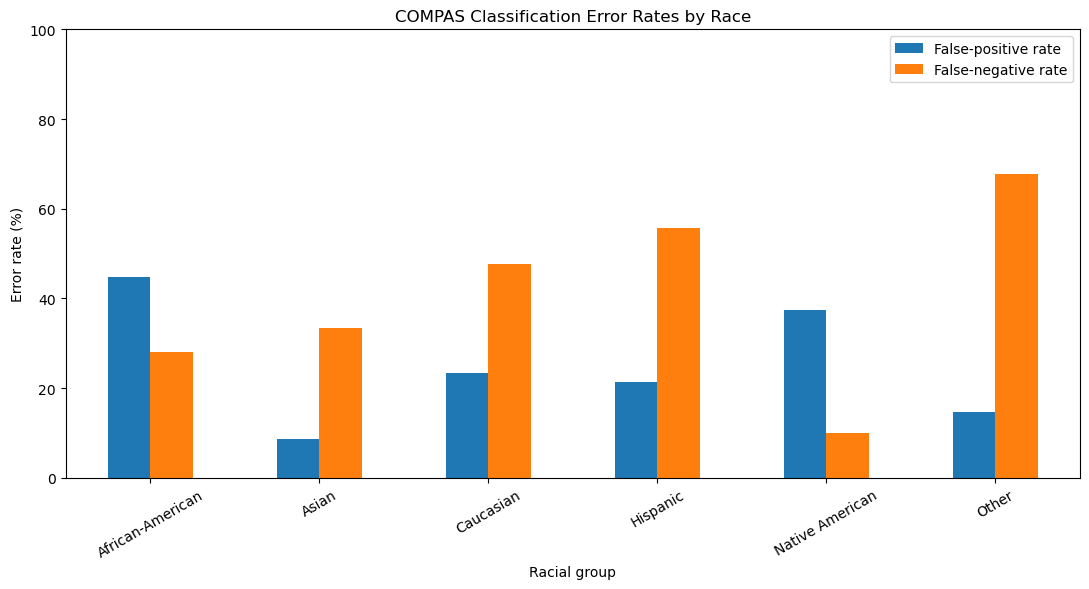

In [9]:
plot_data = fairness_results[
    ["False Positive Rate (%)", "False Negative Rate (%)"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("COMPAS Classification Error Rates by Race")
ax.set_xlabel("Racial group")
ax.set_ylabel("Error rate (%)")
ax.set_ylim(0, 100)
ax.legend(["False-positive rate", "False-negative rate"])
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [10]:
actual = analysis_df["actual_rearrest"]
predicted = analysis_df["predicted_high_risk"]

tp = ((actual == 1) & (predicted == 1)).sum()
tn = ((actual == 0) & (predicted == 0)).sum()
fp = ((actual == 0) & (predicted == 1)).sum()
fn = ((actual == 1) & (predicted == 0)).sum()

accuracy = (tp + tn) / len(analysis_df) * 100
precision = tp / (tp + fp) * 100
recall = tp / (tp + fn) * 100

print("Overall COMPAS classification metrics")
print("-------------------------------------")
print(f"True positives: {tp}")
print(f"True negatives: {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"Accuracy: {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall: {recall:.2f}%")

Overall COMPAS classification metrics
-------------------------------------
True positives: 2035
True negatives: 2681
False positives: 1282
False negatives: 1216
Accuracy: 65.37%
Precision: 61.35%
Recall: 62.60%


In [11]:
threshold_results = []

actual = analysis_df["actual_rearrest"]

for threshold in [4, 5, 6, 7]:
    predicted = (
        analysis_df["decile_score"] >= threshold
    ).astype(int)

    tp = ((actual == 1) & (predicted == 1)).sum()
    tn = ((actual == 0) & (predicted == 0)).sum()
    fp = ((actual == 0) & (predicted == 1)).sum()
    fn = ((actual == 1) & (predicted == 0)).sum()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy (%)": (tp + tn) / len(analysis_df) * 100,
        "False Positive Rate (%)": (
            fp / (fp + tn) * 100 if (fp + tn) else 0
        ),
        "False Negative Rate (%)": (
            fn / (fn + tp) * 100 if (fn + tp) else 0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(2))

,Threshold,Accuracy (%),False Positive Rate (%),False Negative Rate (%)
0,4,63.97,43.33,27.13
1,5,65.37,32.35,37.40
2,6,65.77,23.39,47.43
3,7,64.74,16.25,58.44


In [12]:
print(threshold_df.to_string(index=False))

 Threshold  Accuracy (%)  False Positive Rate (%)  False Negative Rate (%)
         4     63.972831                43.325763                27.130114
         5     65.372886                32.349230                37.403876
         6     65.774882                23.391370                47.431560
         7     64.735237                16.250315                58.443556


In [13]:
race_threshold_results = []

for threshold in [4, 5, 6, 7]:
    for race, group in analysis_df.groupby("race"):
        actual = group["actual_rearrest"]
        predicted = (group["decile_score"] >= threshold).astype(int)

        tn = ((actual == 0) & (predicted == 0)).sum()
        fp = ((actual == 0) & (predicted == 1)).sum()

        fpr = fp / (fp + tn) * 100 if (fp + tn) > 0 else 0

        race_threshold_results.append({
            "Threshold": threshold,
            "Race": race,
            "Records": len(group),
            "False Positive Rate (%)": fpr
        })

race_threshold_df = pd.DataFrame(race_threshold_results)

display(
    race_threshold_df.pivot(
        index="Race",
        columns="Threshold",
        values="False Positive Rate (%)"
    ).round(2)
)

Threshold,4,5,6,7
Race,,,,
African-American,56.43,44.85,34.32,24.90
Asian,8.70,8.70,8.70,4.35
Caucasian,35.01,23.45,14.72,9.14
Hispanic,29.88,21.48,15.56,11.60
Native American,37.50,37.50,37.50,25.00
Other,23.36,14.75,9.84,4.51


In [14]:
major_groups = fairness_results.loc[
    ["African-American", "Caucasian"],
    [
        "Records",
        "False Positive Rate (%)",
        "False Negative Rate (%)"
    ]
].copy()

major_groups["FPR gap vs Caucasian (percentage points)"] = (
    major_groups["False Positive Rate (%)"]
    - major_groups.loc["Caucasian", "False Positive Rate (%)"]
)

display(major_groups.round(2))

,Records,False Positive Rate (%),False Negative Rate (%),FPR gap vs Caucasian (percentage points)
race,,,,
African-American,3696.0,44.85,27.99,21.39
Caucasian,2454.0,23.45,47.72,0.00


In [15]:
original_risk_distribution = pd.crosstab(
    df["race"],
    df["score_text"],
    normalize="index"
) * 100

print("Original COMPAS risk categories by race (%)")
display(original_risk_distribution.round(2))

Original COMPAS risk categories by race (%)


score_text,High,Low,Medium
race,,,
African-American,27.73,41.18,31.09
Asian,9.38,75.00,15.62
Caucasian,11.25,65.20,23.55
Hispanic,10.52,70.17,19.31
Native American,33.33,33.33,33.33
Other,6.90,79.05,14.06


In [17]:
import math

ci_results = []

for race, group in analysis_df.groupby("race"):
    actual = group["actual_rearrest"]
    predicted = group["predicted_high_risk"]

    fp = ((actual == 0) & (predicted == 1)).sum()
    tn = ((actual == 0) & (predicted == 0)).sum()

    n = fp + tn
    p = fp / n

    # Wilson 95% confidence interval
    z = 1.96
    denominator = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denominator
    margin = (
        z * math.sqrt(
            (p * (1 - p) / n) + (z**2 / (4 * n**2))
        ) / denominator
    )

    ci_results.append({
        "Race": race,
        "Records": len(group),
        "FPR (%)": p * 100,
        "95% CI lower (%)": (centre - margin) * 100,
        "95% CI upper (%)": (centre + margin) * 100
    })

ci_df = pd.DataFrame(ci_results)

print("False-positive rates with 95% confidence intervals")
display(ci_df.round(2))

False-positive rates with 95% confidence intervals


,Race,Records,FPR (%),95% CI lower (%),95% CI upper (%)
0,African-American,3696,44.85,42.56,47.16
1,Asian,32,8.70,2.42,26.80
2,Caucasian,2454,23.45,21.37,25.67
3,Hispanic,637,21.48,17.76,25.74
4,Native American,18,37.50,13.68,69.43
5,Other,377,14.75,10.85,19.75


In [18]:
from math import sqrt

aa = analysis_df[analysis_df["race"] == "African-American"]
ca = analysis_df[analysis_df["race"] == "Caucasian"]

def get_fpr_and_se(group):
    actual = group["actual_rearrest"]
    predicted = group["predicted_high_risk"]

    fp = ((actual == 0) & (predicted == 1)).sum()
    tn = ((actual == 0) & (predicted == 0)).sum()

    n = fp + tn
    p = fp / n

    se = sqrt(p * (1 - p) / n)
    return p, se

p_aa, se_aa = get_fpr_and_se(aa)
p_ca, se_ca = get_fpr_and_se(ca)

difference = p_aa - p_ca
se_difference = sqrt(se_aa**2 + se_ca**2)

lower = difference - 1.96 * se_difference
upper = difference + 1.96 * se_difference

print("African-American FPR:", round(p_aa * 100, 2), "%")
print("Caucasian FPR:", round(p_ca * 100, 2), "%")
print("Difference:", round(difference * 100, 2), "percentage points")
print(
    "Approximate 95% CI for difference:",
    round(lower * 100, 2), "to", round(upper * 100, 2),
    "percentage points"
)

African-American FPR: 44.85 %
Caucasian FPR: 23.45 %
Difference: 21.39 percentage points
Approximate 95% CI for difference: 18.24 to 24.54 percentage points


In [19]:
from math import sqrt
from scipy.stats import norm

def get_fp_counts(group):
    actual = group["actual_rearrest"]
    predicted = group["predicted_high_risk"]

    fp = ((actual == 0) & (predicted == 1)).sum()
    tn = ((actual == 0) & (predicted == 0)).sum()

    return fp, fp + tn

aa_fp, aa_n = get_fp_counts(
    analysis_df[analysis_df["race"] == "African-American"]
)

ca_fp, ca_n = get_fp_counts(
    analysis_df[analysis_df["race"] == "Caucasian"]
)

p1 = aa_fp / aa_n
p2 = ca_fp / ca_n

pooled_p = (aa_fp + ca_fp) / (aa_n + ca_n)

se = sqrt(
    pooled_p * (1 - pooled_p) *
    (1 / aa_n + 1 / ca_n)
)

z_stat = (p1 - p2) / se
p_value = 2 * norm.sf(abs(z_stat))

print("Z statistic:", round(z_stat, 3))
print("P-value:", f"{p_value:.6g}")

Z statistic: 12.78
P-value: 2.11349e-37


In [20]:
import pandas as pd

risk_outcome = pd.crosstab(
    analysis_df["score_text"],
    analysis_df["actual_rearrest"],
    normalize="index"
) * 100

risk_outcome.columns = [
    "No Recorded Rearrest (%)",
    "Recorded Rearrest (%)"
]

print(risk_outcome.round(2))

            No Recorded Rearrest (%)  Recorded Rearrest (%)
score_text                                                 
High                           28.65                  71.35
Low                            68.80                  31.20
Medium                         45.98                  54.02


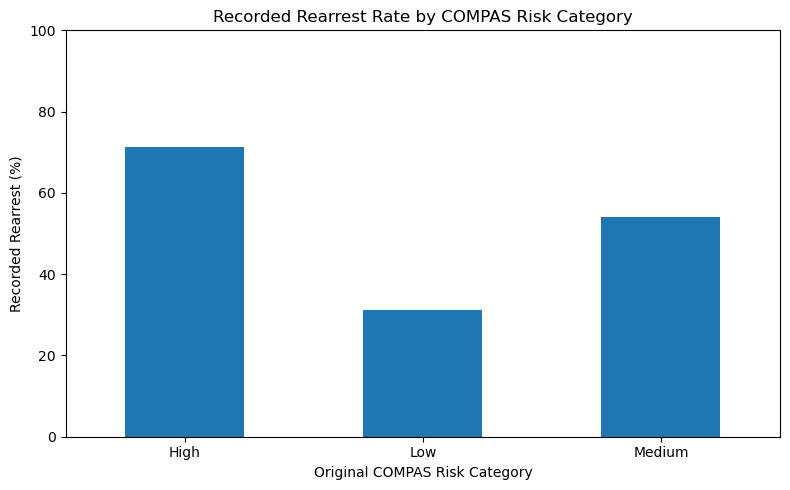

In [21]:
import matplotlib.pyplot as plt

risk_outcome["Recorded Rearrest (%)"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Recorded Rearrest Rate by COMPAS Risk Category")
plt.xlabel("Original COMPAS Risk Category")
plt.ylabel("Recorded Rearrest (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd

comparison_results = []

for race in ["African-American", "Caucasian", "Hispanic",
             "Asian", "Native American", "Other"]:

    group = analysis_df[analysis_df["race"] == race]
    actual = group["actual_rearrest"]

    methods = {
        "Chosen threshold >= 5":
            group["decile_score"] >= 5,
        "Original COMPAS High category":
            group["score_text"] == "High"
    }

    for method, predicted in methods.items():
        predicted = predicted.astype(int)

        fp = ((actual == 0) & (predicted == 1)).sum()
        tn = ((actual == 0) & (predicted == 0)).sum()
        fn = ((actual == 1) & (predicted == 0)).sum()
        tp = ((actual == 1) & (predicted == 1)).sum()

        fpr = fp / (fp + tn) * 100 if fp + tn else 0
        fnr = fn / (fn + tp) * 100 if fn + tp else 0

        comparison_results.append({
            "Race": race,
            "Method": method,
            "Records": len(group),
            "FPR (%)": round(fpr, 2),
            "FNR (%)": round(fnr, 2)
        })

comparison_df = pd.DataFrame(comparison_results)

print(comparison_df.to_string(index=False))

            Race                        Method  Records  FPR (%)  FNR (%)
African-American         Chosen threshold >= 5     3696    44.85    27.99
African-American Original COMPAS High category     3696    15.82    61.02
       Caucasian         Chosen threshold >= 5     2454    23.45    47.72
       Caucasian Original COMPAS High category     2454     5.44    79.81
        Hispanic         Chosen threshold >= 5      637    21.48    55.60
        Hispanic Original COMPAS High category      637     7.16    83.62
           Asian         Chosen threshold >= 5       32     8.70    33.33
           Asian Original COMPAS High category       32     4.35    77.78
 Native American         Chosen threshold >= 5       18    37.50    10.00
 Native American Original COMPAS High category       18    12.50    50.00
           Other         Chosen threshold >= 5      377    14.75    67.67
           Other Original COMPAS High category      377     2.46    84.96


In [23]:
from math import sqrt
from scipy.stats import norm

aa = analysis_df[
    analysis_df["race"] == "African-American"
]

ca = analysis_df[
    analysis_df["race"] == "Caucasian"
]

def get_fp_counts(group):
    actual = group["actual_rearrest"]
    predicted = group["decile_score"] >= 5

    fp = ((actual == 0) & predicted).sum()
    tn = ((actual == 0) & (~predicted)).sum()

    return int(fp), int(fp + tn)

aa_fp, aa_n = get_fp_counts(aa)
ca_fp, ca_n = get_fp_counts(ca)

p1 = aa_fp / aa_n
p2 = ca_fp / ca_n

difference = p1 - p2

# Approximate 95% confidence interval
se1 = sqrt(p1 * (1 - p1) / aa_n)
se2 = sqrt(p2 * (1 - p2) / ca_n)
se_difference = sqrt(se1**2 + se2**2)

lower = difference - 1.96 * se_difference
upper = difference + 1.96 * se_difference

# Two-proportion z-test
pooled_p = (aa_fp + ca_fp) / (aa_n + ca_n)

pooled_se = sqrt(
    pooled_p * (1 - pooled_p) *
    (1 / aa_n + 1 / ca_n)
)

z_stat = difference / pooled_se
p_value = 2 * norm.sf(abs(z_stat))

print(f"African-American FPR: {p1 * 100:.2f}%")
print(f"Caucasian FPR: {p2 * 100:.2f}%")
print(f"Difference: {difference * 100:.2f} percentage points")
print(
    f"Approximate 95% CI: "
    f"{lower * 100:.2f} to {upper * 100:.2f} percentage points"
)
print(f"Z statistic: {z_stat:.2f}")
print(f"P-value: {p_value:.6g}")

African-American FPR: 44.85%
Caucasian FPR: 23.45%
Difference: 21.39 percentage points
Approximate 95% CI: 18.24 to 24.54 percentage points
Z statistic: 12.78
P-value: 2.11349e-37


In [25]:
report_race_table = fairness_results[
    ["Records", "False Positive Rate (%)", "False Negative Rate (%)"]
].copy()

print("TABLE 1: CLASSIFICATION ERROR RATES BY RACE")
print(report_race_table.round(2).to_string())

# Table 2: Threshold sensitivity
print("\nTABLE 2: PERFORMANCE AT DIFFERENT THRESHOLDS")
print(threshold_df.round(2).to_string())

TABLE 1: CLASSIFICATION ERROR RATES BY RACE
                  Records  False Positive Rate (%)  False Negative Rate (%)
race                                                                       
African-American   3696.0                    44.85                    27.99
Asian                32.0                     8.70                    33.33
Caucasian          2454.0                    23.45                    47.72
Hispanic            637.0                    21.48                    55.60
Native American      18.0                    37.50                    10.00
Other               377.0                    14.75                    67.67

TABLE 2: PERFORMANCE AT DIFFERENT THRESHOLDS
   Threshold  Accuracy (%)  False Positive Rate (%)  False Negative Rate (%)
0          4         63.97                    43.33                    27.13
1          5         65.37                    32.35                    37.40
2          6         65.77                    23.39                    

In [26]:
analysis_df["threshold_high_risk"] = (
    analysis_df["decile_score"] >= 5
).astype(int)

analysis_df["compas_high_risk"] = (
    analysis_df["score_text"] == "High"
).astype(int)

print("High-risk classifications using decile_score >= 5:")
print(analysis_df["threshold_high_risk"].value_counts())

print("\nHigh-risk classifications using COMPAS score_text:")
print(analysis_df["compas_high_risk"].value_counts())

print("\nNumber of records classified differently:")
print(
    (analysis_df["threshold_high_risk"] !=
     analysis_df["compas_high_risk"]).sum()
)

High-risk classifications using decile_score >= 5:
threshold_high_risk
0    3897
1    3317
Name: count, dtype: int64

High-risk classifications using COMPAS score_text:
compas_high_risk
0    5811
1    1403
Name: count, dtype: int64

Number of records classified differently:
1914


<ipython-input-27-f133c41b2992>:15: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig("COMPAS_Classification_Error_Rates.png",
<ipython-input-27-f133c41b2992>:15: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig("COMPAS_Classification_Error_Rates.png",


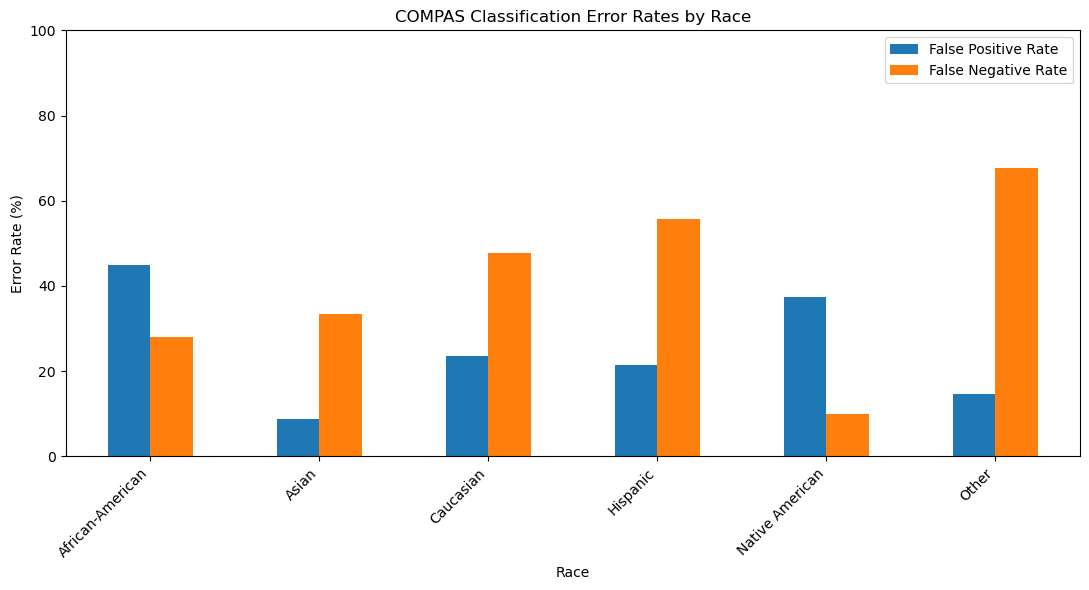

In [27]:
import matplotlib.pyplot as plt

ax = fairness_results[
    ["False Positive Rate (%)", "False Negative Rate (%)"]
].plot(kind="bar", figsize=(11, 6))

ax.set_title("COMPAS Classification Error Rates by Race")
ax.set_xlabel("Race")
ax.set_ylabel("Error Rate (%)")
ax.set_ylim(0, 100)
ax.legend(["False Positive Rate", "False Negative Rate"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("COMPAS_Classification_Error_Rates.png",
            dpi=300, bbox_inches="tight")

plt.show()